# Case 3, chapter 8: Moving the model to lending, and opening the envelope

*Applies chapter 4 (the transfer paragraph: what changes, what stays, what would leak), chapter 1 (the justification) and chapter 5 (reading the memo aloud under challenge) to German Credit and to the test slice sealed since Monday.*

**Who needs the answer.** Rohan Desai, head of risk at Kalpa Financial, who sits on Monday's committee to learn what carries over to his loan book, and the whole committee, which hears one honest number from data nobody has touched.

**The questions on the way.** Where does the lending threshold sit when a bad loan costs five times a good applicant turned away, and where at Rohan's twenty times? Which column name looks like Wednesday's leak and is not one? What does the chosen model score on the sealed test slice, once? Does the whole memo fit in under 300 words?

**What you will be able to do.** Set a lending threshold on P(repay) from a documented cost matrix, write the transfer paragraph from your own numbers, and report a test score that was never used to choose anything.

**Search terms.** credit risk model, cost matrix, German credit dataset, test set, model card.

## What does German Credit hold, and what does its own documentation ask for?

German Credit (Statlog, Hans Hofmann) holds 1,000 loan applicants from Hamburg in 1994, 700 rated good and 300 bad. Its documentation on the UCI page and on OpenML says the data "requires use of a cost matrix": classing a bad customer as good costs 5, and classing a good customer as bad costs 1. OpenML record checked: https://www.openml.org/api/v1/json/data/31 (verified 28 October 2026). The first run downloads about 36 KB and caches it.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)

import pathlib
import numpy as np, pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
credit = fetch_openml(name="credit-g", version=1, as_frame=True, data_home=str(CACHE / "openml")).frame
repaid = (credit["class"] == "good").astype(int)          # the positive class is now the good outcome
Xc = credit.drop(columns="class")
print(credit.shape, "good:", int(repaid.sum()), "bad:", int((1 - repaid).sum()))

(1000, 21) good: 700 bad: 300


In [2]:
check("1,000 applicants, 700 good and 300 bad, as documented", len(credit) == 1000 and repaid.sum() == 700)
check("no missing values to impute", not credit.isna().any().any())

PASS  1,000 applicants, 700 good and 300 bad, as documented
PASS  no missing values to impute


## The options: where should the lending line sit?

The same machinery as the nudge: a probability, a threshold, a bill. The quantity is now P(repay), and the costly mistake has changed sides: a false approval (a bad loan granted) costs 5, a wrongful rejection (a good applicant turned away) costs 1.

**Predict before you run.** Approve when P(repay) is above which number? a) 0.50, the default; b) 0.17, since 1 / (1 + 5) = 0.17; c) 0.83, since 5 / (5 + 1) = 0.83; d) 0.03, Tuesday's nudge threshold.

In [3]:
num = [c for c in Xc if pd.api.types.is_numeric_dtype(Xc[c])]
cat = [c for c in Xc if c not in num]
tr, va = train_test_split(credit.index, test_size=0.3, stratify=repaid, random_state=42)
lender = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), num),
                                               ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
                   ("model", LogisticRegression(max_iter=3000))]).fit(Xc.loc[tr], repaid[tr])
p_repay, yv = lender.predict_proba(Xc.loc[va])[:, 1], repaid[va].to_numpy()
print(f"validation applicants {len(yv)}, good {yv.sum()}, AUC {roc_auc_score(yv, p_repay):.3f}")

def lend_bill(t, bad_cost, good_cost):
    lend = p_repay >= t
    fa, wr = int((lend & (yv == 0)).sum()), int((~lend & (yv == 1)).sum())
    return {"approved": int(lend.sum()), "false approvals": fa, "wrongful rejections": wr,
            "cost": bad_cost * fa + good_cost * wr}
GC_T, ROHAN_T = 5 / 6, 60000 / 63000
pd.DataFrame({"0.50 default": lend_bill(0.5, 5, 1), f"{GC_T:.3f} German Credit 5:1": lend_bill(GC_T, 5, 1),
              "approve everyone": lend_bill(0.0, 5, 1)}).T

validation applicants 300, good 210, AUC 0.783


,approved,false approvals,wrongful rejections,cost
0.50 default,226,47,31,266
0.833 German Credit 5:1,128,13,95,160
approve everyone,300,90,0,450


**What happened.** The answer is c. At 0.5 the 300 applicants cost 266 units; at 0.833 they cost 160, about 40 percent less, with fewer than half as many loans approved. Option b is the commonest slip: it puts the cost ratio on the wrong side, which is what happens when the positive class flips and the formula is copied without asking which mistake is the expensive one. Stated on the same quantity, the two businesses read: nudge when P(buy) is above 0.03; lend when P(repay) is above 0.83.

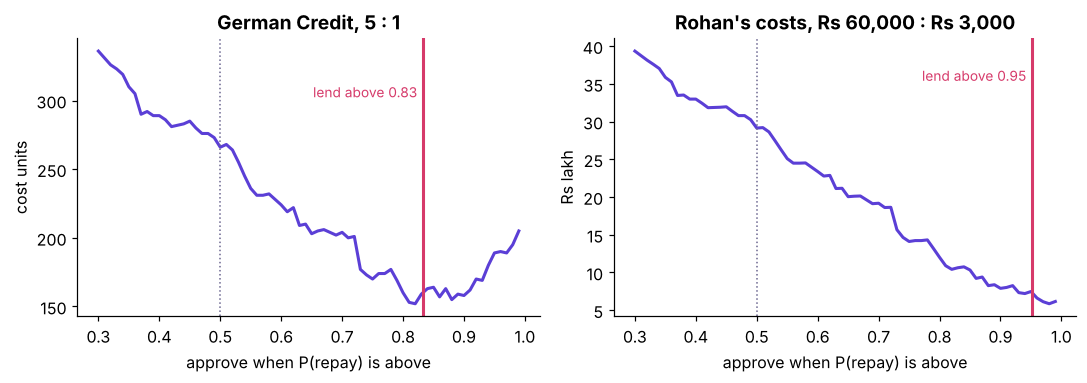

cheapest threshold in the sweep (5:1): 0.82; Rohan's costs at 0.952: Rs 690,000


In [4]:
ts = np.linspace(0.30, 0.99, 70)
gc = [lend_bill(t, 5, 1)["cost"] for t in ts]
ro = [lend_bill(t, 60000, 3000)["cost"] / 1e5 for t in ts]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, vals, t_star, title, unit in [(axes[0], gc, GC_T, "German Credit, 5 : 1", "cost units"),
                                      (axes[1], ro, ROHAN_T, "Rohan's costs, Rs 60,000 : Rs 3,000", "Rs lakh")]:
    ax.plot(ts, vals, color=VIOLET, lw=2)
    ax.axvline(0.5, color=MUTED, ls=":", lw=1); ax.axvline(t_star, color=ROSE, lw=2)
    ax.text(t_star - 0.01, max(vals) * 0.9, f"lend above {t_star:.2f}", color=ROSE, ha="right", fontsize=9)
    ax.set_xlabel("approve when P(repay) is above"); ax.set_ylabel(unit); ax.set_title(title)
plt.tight_layout(); plt.show()
best = ts[int(np.argmin(gc))]
print(f"cheapest threshold in the sweep (5:1): {best:.2f}; Rohan's costs at 0.952: Rs {lend_bill(ROHAN_T, 60000, 3000)['cost']:,}")

## Which column looks like a leak and is not one?

German Credit has a column called `duration`. In the bank's file, `duration` was the call's length, known only after the call ended, which is why Wednesday dropped it. Here it is the loan's term in months, agreed on the application form, so it is known at the moment of decision. The prediction-time question decides, never the column's name. The column that would leak in Rohan's feed is anything written after the approval: days past due, a collections flag, a restructured-loan marker.

In [5]:
print(credit["duration"].describe()[["min", "50%", "max"]])
check("German Credit's duration reads as a loan term in months (4 to 72)", credit["duration"].between(4, 72).all())
check("the 5:1 threshold costs less than the 0.5 default", lend_bill(GC_T, 5, 1)["cost"] < lend_bill(0.5, 5, 1)["cost"])

min     4.0
50%    18.0
max    72.0
Name: duration, dtype: float64
PASS  German Credit's duration reads as a loan term in months (4 to 72)
PASS  the 5:1 threshold costs less than the 0.5 default


## Opening the envelope: what does the chosen model score on data nobody has touched?

The test slice was sealed on Monday, before any model existed, and every request to peek was pointed at the card on the wall. The model is chosen (logistic, from case 1), so the test slice is opened once and the number goes into the memo whatever it says. A second look, or a reselection after it, would turn it back into a validation number.

In [6]:
# The Week 5 pipeline: the same file, columns and split every case notebook starts from.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

bank = load_bank()
# Wednesday's honest set: no duration, and pdays split into a flag and the days for those contacted.
bank["never_contacted"] = (bank["pdays"] == 999).astype(int)
bank["days_since"] = bank["pdays"].where(bank["pdays"] != 999, 0)
COLS = PROFILE + HISTORY + ECONOMY + ["never_contacted", "days_since"]
X, y = bank[COLS], (bank["y"] == "yes").astype(int)

# The test slice is sealed first (the envelope on the wall); the rest splits 75/25.
rest, test = train_test_split(bank.index, test_size=0.20, stratify=y, random_state=42)
train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=42)
NUM = [c for c in COLS if pd.api.types.is_numeric_dtype(bank[c])]
CAT = [c for c in COLS if c not in NUM]

def logistic():
    prep = ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=3000))])

print(f"{len(bank):,} rows; train {len(train):,}, validation {len(val):,}, test {len(test):,} (sealed)")
print(f"buyers in validation: {y[val].sum():,} of {len(val):,} ({y[val].mean():.1%})")

chosen = logistic().fit(X.loc[train], y[train])
p_val, p_test = chosen.predict_proba(X.loc[val])[:, 1], chosen.predict_proba(X.loc[test])[:, 1]
yval, ytest = y[val].to_numpy(), y[test].to_numpy()
def found_top(yt, p, k=1000):
    return int(yt[np.argsort(-p, kind="stable")[:k]].sum())
envelope = pd.DataFrame({
    "AUC": [round(roc_auc_score(yval, p_val), 3), round(roc_auc_score(ytest, p_test), 3)],
    "buyers in top 1,000": [found_top(yval, p_val), found_top(ytest, p_test)],
    "at random": [round(yval.mean() * 1000), round(ytest.mean() * 1000)],
}, index=["validation (used to choose)", "test (opened once)"])
envelope

41,188 rows; train 24,712, validation 8,238, test 8,238 (sealed)
buyers in validation: 928 of 8,238 (11.3%)


,AUC,"buyers in top 1,000",at random
validation (used to choose),0.795,462,113
test (opened once),0.801,482,113


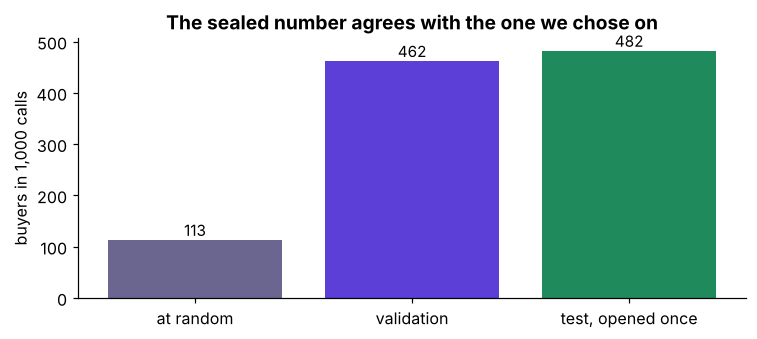

PASS  the test AUC sits within 0.02 of validation
PASS  the test top 1,000 finds at least four times the random count


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
labels = ["at random", "validation", "test, opened once"]
vals = [envelope.loc["test (opened once)", "at random"], envelope.iloc[0, 1], envelope.iloc[1, 1]]
ax.bar(labels, vals, color=[MUTED, VIOLET, GREEN])
for i, v in enumerate(vals):
    ax.text(i, v + 8, f"{v}", ha="center", fontsize=10)
ax.set_ylabel("buyers in 1,000 calls"); ax.set_title("The sealed number agrees with the one we chose on")
plt.tight_layout(); plt.show()
check("the test AUC sits within 0.02 of validation", abs(envelope.iloc[0, 0] - envelope.iloc[1, 0]) < 0.02)
check("the test top 1,000 finds at least four times the random count", envelope.iloc[1, 1] > 4 * envelope.iloc[1, 2])

## Does the whole memo fit in under 300 words?

The memo is the four parts from chapter 1, then the transfer paragraph for Rohan. Every sentence carries a number from this week's runs. The cell counts its words, since the after-class version must stay under 300 and the spoken version must fit in ninety seconds.

In [8]:
memo = f'''CLAIM. Call the 1,000 customers the logistic model ranks highest in each list of about 8,000.
EVIDENCE. On the sealed test slice it found {envelope.iloc[1, 1]} buyers in 1,000 calls, against {envelope.iloc[1, 2]} at random (AUC {envelope.iloc[1, 0]}).
On validation, boosting found 13 more in 1,000, a gap whose band reaches zero, so the simpler model is recommended.
Without the budget, at Rs 40 against Rs 1,200, any model's bill sits within 4 percent of calling everyone.
CAVEAT. Trained on May 2008 to April 2009 and scored to November 2010, it promised 16 in 100 while 25 bought,
and the bill rose above calling everyone. It ranks blue-collar customers and telephone contacts worst.
ACTION. Run the 1,000-call list monthly. If the share of called customers who subscribe sits more than
10 points from the promise two months running, Kavya pauses the list and the model goes back for a refit.
TRANSFER. For Rohan the pipeline, the sealed test, the baseline and the bill stay. The target, the costs
and the threshold change: lend when P(repay) is above 0.95 at his 20 : 1, as 0.83 does at German Credit's 5 : 1.
Anything written after approval, such as days past due, would leak; a column named duration need not.'''
print(memo)
words = len(memo.split())
print("\nwords:", words)
check("the memo stays under 300 words", words < 300)
check("all five parts are present", all(k in memo for k in ["CLAIM.", "EVIDENCE.", "CAVEAT.", "ACTION.", "TRANSFER."]))

CLAIM. Call the 1,000 customers the logistic model ranks highest in each list of about 8,000.
EVIDENCE. On the sealed test slice it found 482 buyers in 1,000 calls, against 113 at random (AUC 0.801).
On validation, boosting found 13 more in 1,000, a gap whose band reaches zero, so the simpler model is recommended.
Without the budget, at Rs 40 against Rs 1,200, any model's bill sits within 4 percent of calling everyone.
CAVEAT. Trained on May 2008 to April 2009 and scored to November 2010, it promised 16 in 100 while 25 bought,
and the bill rose above calling everyone. It ranks blue-collar customers and telephone contacts worst.
ACTION. Run the 1,000-call list monthly. If the share of called customers who subscribe sits more than
10 points from the promise two months running, Kavya pauses the list and the model goes back for a refit.
TRANSFER. For Rohan the pipeline, the sealed test, the baseline and the bill stay. The target, the costs
and the threshold change: lend when P(repay) is ab

## What did this chapter establish?

| Question | Answer from this run |
|---|---|
| The lending line at 5 : 1 | Lend when P(repay) is above 0.83; the cost falls about 40 percent against the 0.5 default |
| The lending line at Rohan's 20 : 1 | Lend when P(repay) is above 0.95 |
| The name trap | German Credit's `duration` is a loan term, known at application, so it stays |
| The envelope | The sealed test agrees with validation; that one number goes in the memo |

Build 2 next week is Rohan's business, with his constraint written into the brief; this paragraph is where it starts.